# K-Means CPU Baseline — V3 Aligned

This CPU baseline is aligned with GPU Atomic V3 and GPU Reduction V3.

For a fair comparison it uses:

- the exact initial centroid matrices saved by Atomic V3,
- float64 feature data (matching the GPU notebooks),
- `MAX_ITER = 400`,
- centroid movement tolerance `1e-4`,
- assignment-change fraction tolerance `1e-4` (0.01%),
- 3 consecutive stable-assignment iterations,
- the same empty-cluster policy: keep the previous centroid.

It retains the CPU notebook's fixed-iteration warm-up/repeat timing protocol for
a robust CPU per-iteration baseline.


## 1. Colab setup

In [1]:
import sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

for pkg in ("numba", "threadpoolctl", "psutil"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("Running on Colab" if IN_COLAB else "Running locally")

Mounted at /content/drive
Running on Colab


## 2. Configuration

In [2]:

import os
from pathlib import Path
import numpy as np

if IN_COLAB:
    DATA_DIR = Path("/content/drive/MyDrive/kmeans_data")
    OUT_DIR = DATA_DIR / "results_cpu_baseline_v3_aligned"
else:
    DATA_DIR = Path(".")
    OUT_DIR = Path("results_cpu_baseline_v3_aligned")

SUBFOLDER_PATTERN = "rows*"
FILE_PATTERN = "synthetic_data_*_rows_*_cols_*_clusters.csv"
SIZES = None
RESUME = True

ID_COLUMN = "auto"
LABEL_COLUMN = "auto"
SAVE_ASSIGNMENTS = True
ASSIGNMENTS_DIR = (
    Path("/content/assignments_cpu_baseline_v3_aligned")
    if IN_COLAB
    else OUT_DIR / "assignments"
)
HISTORY_DIR = OUT_DIR / "history"

# -----------------------------------------------------------------
# Canonical starting centroids
# -----------------------------------------------------------------
# These are the exact files produced by the completed Atomic V3 run.
INIT_DIR = DATA_DIR / "results_gpu_atomic_v3"
REQUIRE_CANONICAL_INIT = True
SEED = 42  # recorded for experiment metadata; canonical files determine C0

# -----------------------------------------------------------------
# Same convergence rules as GPU Atomic/Reduction V3
# -----------------------------------------------------------------
TOL = 1e-4
ASSIGNMENT_CHANGE_FRACTION_TOL = 1e-4
ASSIGNMENT_STABLE_ITERS = 3
MAX_ITER = 400

# CPU fixed-iteration timing protocol
WARMUP_RUNS = 1
BENCH_REPEATS = 5
BENCH_ITERS = 20
BENCH_MIN_SECONDS = 0.5
BENCH_MAX_ITERS = 20_000

N_THREADS = os.cpu_count()
THREAD_CANDIDATES = None

# Match GPU notebooks numerically.
DTYPE = np.float64


In [3]:
import os, re
base = str(DATA_DIR)
print("DATA_DIR:", base)
for root, dirs, files in os.walk(base):
    depth = root[len(base):].count(os.sep)
    if depth > 3:
        continue
    print("  " * depth + (os.path.basename(root) or root) + f"/  ({len(files)} files)")
    for f in files:
        if "10000000" in f or "10m" in f.lower():
            print("  " * (depth + 1) + "->", f)

print("\nAnything named like 10M elsewhere in MyDrive:")
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for name in dirs + files:
        if "10000000" in name or re.search(r"10m", name, re.I):
            print("  ", os.path.join(root, name))

DATA_DIR: /content/drive/MyDrive/kmeans_data
kmeans_data/  (3 files)
  rows1000000/  (3 files)
  rows10000/  (3 files)
  rows100000/  (3 files)
  rows5000000/  (3 files)
  rows50000/  (3 files)
  rows10000000/  (3 files)
    -> synthetic_data_10000000_rows_10_cols_13_clusters.csv
    -> synthetic_data_10000000_rows_10_cols_15_clusters.csv
    -> synthetic_data_10000000_rows_10_cols_17_clusters.csv
  results_gpu_atomic/  (40 files)
    -> initial_centroids_synthetic_data_10000000_rows_10_cols_13_clusters.csv
    -> final_results_synthetic_data_10000000_rows_10_cols_13_clusters.csv
    -> initial_centroids_synthetic_data_10000000_rows_10_cols_15_clusters.csv
    -> final_results_synthetic_data_10000000_rows_10_cols_15_clusters.csv
    -> initial_centroids_synthetic_data_10000000_rows_10_cols_17_clusters.csv
    -> final_results_synthetic_data_10000000_rows_10_cols_17_clusters.csv
    assignments/  (18 files)
      -> assignments_synthetic_data_10000000_rows_10_cols_13_clusters.csv
      

## 3. Environment (saved with the results)

In [4]:
import json, platform, re, time, warnings, shutil, zipfile, hashlib
import pandas as pd
from threadpoolctl import threadpool_info, threadpool_limits

try:
    import numba
    from numba import njit, prange
    HAVE_NUMBA = True
    numba.set_num_threads(min(N_THREADS, numba.config.NUMBA_NUM_THREADS))
except ImportError:
    HAVE_NUMBA = False
IMPLEMENTATION = "numba" if HAVE_NUMBA else "numpy"
OUT_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

def cpu_info():
    info = {"cpu_model": platform.processor() or "unknown", "physical_cores": None}
    try:
        if sys.platform == "darwin":
            info["cpu_model"] = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
        elif sys.platform.startswith("linux"):
            for line in open("/proc/cpuinfo"):
                if line.startswith("model name"):
                    info["cpu_model"] = line.split(":", 1)[1].strip()
                    break
        import psutil
        info["physical_cores"] = psutil.cpu_count(logical=False)
        info["ram_gb"] = round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        pass
    return info

ENV = {
    "runtime": "Google Colab (CPU)" if IN_COLAB else "local",
    **cpu_info(),
    "logical_cores": os.cpu_count(),
    "max_threads": N_THREADS,
    "implementation": IMPLEMENTATION,
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "numba": numba.__version__ if HAVE_NUMBA else None,
    "pandas": pd.__version__,
    "blas": [{k: d.get(k) for k in ("internal_api", "version", "num_threads")} for d in threadpool_info()],
    "settings": {"TOL": TOL, "MAX_ITER": MAX_ITER, "WARMUP_RUNS": WARMUP_RUNS, "BENCH_REPEATS": BENCH_REPEATS,
                 "BENCH_ITERS": BENCH_ITERS, "BENCH_MIN_SECONDS": BENCH_MIN_SECONDS, "SEED": SEED,
                 "canonical_init_dir": str(INIT_DIR),
                 "assignment_change_fraction_tolerance": ASSIGNMENT_CHANGE_FRACTION_TOL,
                 "assignment_stable_iterations": ASSIGNMENT_STABLE_ITERS,
                 "THREAD_CANDIDATES": THREAD_CANDIDATES or sorted({1, N_THREADS}),
                 "dtype": np.dtype(DTYPE).name, "centroid_sums": "float64"},
}
with open(OUT_DIR / "environment.json", "w") as fh:
    json.dump(ENV, fh, indent=2)
if not HAVE_NUMBA:
    warnings.warn("Numba is not available: falling back to the NumPy implementation, which is much slower.")
ENV

{'runtime': 'Google Colab (CPU)',
 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz',
 'physical_cores': 1,
 'ram_gb': 13.6,
 'logical_cores': 2,
 'max_threads': 2,
 'implementation': 'numba',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'python': '3.13.16',
 'numpy': '2.1.3',
 'numba': '0.61.2',
 'pandas': '2.2.3',
 'blas': [{'internal_api': 'openblas', 'version': '0.3.27', 'num_threads': 2}],
 'settings': {'TOL': 0.0001,
  'MAX_ITER': 400,
  'WARMUP_RUNS': 1,
  'BENCH_REPEATS': 5,
  'BENCH_ITERS': 20,
  'BENCH_MIN_SECONDS': 0.5,
  'SEED': 42,
  'canonical_init_dir': '/content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3',
  'assignment_change_fraction_tolerance': 0.0001,
  'assignment_stable_iterations': 3,
  'THREAD_CANDIDATES': [1, 2],
  'dtype': 'float64',
  'centroid_sums': 'float64'}}

## 4. Data loading and starting centroids

Each file holds an `ID` column and 9 feature columns. The 9 features are clustered; the ID is kept aside and used only to write each row's cluster.
Starting centroids are chosen with **k-means++** (each new starting point is picked far from the ones already chosen), generated once per file with `SEED`, saved in `OUT_DIR` and reused on later runs. The CPU and GPU runs therefore start from exactly the same points. Plain random starting points often put two centroids in the same true cluster, which then splits while two other clusters merge.

In [5]:
NAME_RE = re.compile(r"synthetic_data_(\d+)_rows_(\d+)_cols_(\d+)_clusters")
LABEL_NAMES = {"true_label", "label", "labels", "cluster", "clusters", "cluster_id", "target", "class", "y"}
INDEX_NAMES = {"id", "index", "idx", "row", "row_id"}

def parse_name(path):
    m = NAME_RE.search(Path(path).name)
    if not m:
        raise ValueError(f"Unexpected file name: {path}")
    n, cols, k = map(int, m.groups())
    return {"file": m.group(0), "rows": n, "cols": cols, "K": k}

def _inside_out_dir(p):
    try:
        return OUT_DIR.resolve() in Path(p).resolve().parents
    except Exception:
        return False

def find_data_files():
    """Data files in DATA_DIR/<SUBFOLDER_PATTERN>/** (any depth), one per file name."""
    base = Path(DATA_DIR)
    if not base.exists():
        raise FileNotFoundError(f"DATA_DIR does not exist: {base}")
    roots = [d for d in sorted(base.glob(SUBFOLDER_PATTERN)) if d.is_dir()] if SUBFOLDER_PATTERN else [base]
    if not roots:
        raise FileNotFoundError(f"No folders matching {SUBFOLDER_PATTERN!r} in {base}")
    found = {}
    for root in roots:
        for p in sorted(root.rglob(FILE_PATTERN)):
            if _inside_out_dir(p):
                continue
            if p.name in found:
                warnings.warn(f"Duplicate {p.name}: using {found[p.name]}, ignoring {p}")
                continue
            found[p.name] = p
    for p in found.values():                     # folder rows<N> should match <N>_rows in the file name
        for part in p.relative_to(base).parts[:-1]:
            m = re.fullmatch(r"rows_?(\d+)", part)
            if m and int(m.group(1)) != parse_name(p)["rows"]:
                warnings.warn(f"{p}: folder {part} does not match the row count in the file name")
    return sorted(found.values(), key=lambda p: (parse_name(p)["rows"], parse_name(p)["K"]))

def _is_number(tok):
    try:
        float(tok)
        return True
    except ValueError:
        return False

def _detect_header(path):
    """Header = some field in line 1 is text where line 2 has a number (an ID column is text on both lines)."""
    with open(path) as fh:
        l1 = fh.readline().strip().split(",")
        l2 = fh.readline().strip().split(",")
    return 0 if any(not _is_number(a) and _is_number(b) for a, b in zip(l1, l2)) else None

def _looks_like_index(col, values):
    name = str(col).strip().lower()
    if name in INDEX_NAMES or name.startswith("unnamed"):
        return True
    v = values.to_numpy()
    return len(v) > 1 and np.array_equal(v, np.arange(v[0], v[0] + len(v)))

def _read_csv(path, header, **kw):
    # index_col=False: if every row ends with a trailing comma, pandas would otherwise
    # turn the first column into the index and shift all column names by one.
    return pd.read_csv(path, header=header, index_col=False, **kw)

def load_dataset(path, meta):
    """Returns (X float32 features, layout). The ID column is only recorded in `layout`."""
    header = _detect_header(path)
    sniff = _read_csv(path, header, nrows=2000)
    empty = [c for c in sniff.columns if sniff[c].isna().all()]          # e.g. from trailing commas
    cols = [c for c in sniff.columns if c not in empty]
    as_num = {c: pd.to_numeric(sniff[c], errors="coerce") for c in cols}
    numeric = [c for c in cols if as_num[c].notna().all()]
    text = [c for c in cols if c not in numeric]

    if ID_COLUMN == "auto":
        named = [c for c in cols if str(c).strip().lower() in INDEX_NAMES]
        id_col = named[0] if named else (text[0] if len(text) == 1 else None)
    else:
        id_col = ID_COLUMN
        if id_col is not None and id_col not in cols:
            raise ValueError(f"{Path(path).name}: ID column {ID_COLUMN!r} not found in {cols}")
    numeric = [c for c in numeric if c != id_col]
    index_cols = [c for c in numeric if _looks_like_index(c, as_num[c])]
    numeric = [c for c in numeric if c not in index_cols]
    skipped = [c for c in text if c != id_col] + index_cols + empty

    label = None
    if LABEL_COLUMN == "auto":
        named = [c for c in numeric if str(c).strip().lower() in LABEL_NAMES]
        if named:
            label = named[0]
        elif numeric and (as_num[numeric[-1]] == as_num[numeric[-1]].round()).all():
            label = numeric[-1]
    elif LABEL_COLUMN is not None:
        label = LABEL_COLUMN
        if label not in numeric:
            raise ValueError(f"{Path(path).name}: label column {LABEL_COLUMN!r} not found among {numeric}")
    features = [c for c in numeric if c != label]
    if not features:
        raise ValueError(f"{Path(path).name}: no numeric feature columns found")

    df = _read_csv(path, header, usecols=features, dtype={c: DTYPE for c in features})
    X = np.ascontiguousarray(df[features].to_numpy(dtype=DTYPE))
    layout = {"header": header is not None, "id_column": id_col, "feature_columns": features,
              "label_column": label, "skipped": skipped}
    n_cols = len(features) + (label is not None) + (id_col is not None)
    if n_cols != meta["cols"]:
        warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "
                      f"but the file name says {meta['cols']}. Check the layout: {layout}")
    return X, layout

def read_ids(path, layout, n):
    """IDs in file order (row numbers if the file has no ID column)."""
    if layout["id_column"] is None:
        return pd.Series(np.arange(n), name="row")
    header = 0 if layout["header"] else None
    ids = _read_csv(path, header, usecols=[layout["id_column"]], dtype={layout["id_column"]: str})[layout["id_column"]]
    if len(ids) != n:
        raise ValueError(f"{Path(path).name}: {len(ids)} IDs but {n} feature rows")
    return ids.rename("ID")


def initial_centroid_sha256(C):
    arr = np.ascontiguousarray(
        np.asarray(C, dtype=np.float64)
    )
    return hashlib.sha256(arr.tobytes()).hexdigest()


def init_label():
    return f"canonical Atomic V3 from {INIT_DIR}"


def _read_canonical_initial_centroids(path, K, d, feature_cols):
    df = pd.read_csv(path)

    if "cluster" in df.columns:
        df = df.drop(columns=["cluster"])

    if feature_cols and all(c in df.columns for c in feature_cols):
        df = df[list(feature_cols)]
    else:
        df = df.select_dtypes(include=[np.number])

    C = df.to_numpy(dtype=np.float64)

    if C.shape != (K, d):
        raise ValueError(
            f"{path} has shape {C.shape}, expected {(K, d)}"
        )

    return np.ascontiguousarray(C, dtype=DTYPE)


def initial_centroids(meta, X, feature_cols):
    """
    Load the exact centroid matrix produced by Atomic V3.
    No fallback initialization is allowed in the aligned notebook.
    """
    K, d = meta["K"], X.shape[1]

    name = f"initial_centroids_{meta['file']}.csv"
    path = Path(INIT_DIR) / name

    if not path.exists():
        raise FileNotFoundError(
            f"Canonical initialization is missing: {path}\n"
            "Run the Atomic V3 notebook first, or copy its initial_centroids_*.csv "
            "files into results_gpu_atomic_v3."
        )

    C = _read_canonical_initial_centroids(
        path,
        K,
        d,
        feature_cols
    )

    # Keep a copy in the CPU result folder for auditability.
    local = pd.DataFrame(
        C,
        columns=feature_cols
    )
    local.insert(0, "cluster", np.arange(K))
    local.to_csv(
        OUT_DIR / name,
        index=False
    )

    return C, init_label()


**Check the column layout before running everything.** For files laid out as `ID,col_1,...,col_9` you should see `id_column: 'ID'`, the 9 `col_*` columns as features, and `label_column: None`. If not, set `ID_COLUMN` / `LABEL_COLUMN` in the configuration cell.

In [6]:
_files = find_data_files()
print(f"{len(_files)} data files found under {DATA_DIR}")
for _p in _files:
    print("  ", _p.relative_to(DATA_DIR))
if _files:
    _p = _files[0]
    with open(_p) as fh:
        print("\nFirst lines of", _p.name)
        for _ in range(3):
            print("   ", fh.readline().rstrip()[:160])
    _X, _layout = load_dataset(_p, parse_name(_p))
    print("layout:", _layout)
    print("X:", _X.shape, _X.dtype)
    del _X

18 data files found under /content/drive/MyDrive/kmeans_data
   rows10000/synthetic_data_10000_rows_10_cols_3_clusters.csv
   rows10000/synthetic_data_10000_rows_10_cols_5_clusters.csv
   rows10000/synthetic_data_10000_rows_10_cols_7_clusters.csv
   rows50000/synthetic_data_50000_rows_10_cols_7_clusters.csv
   rows50000/synthetic_data_50000_rows_10_cols_9_clusters.csv
   rows50000/synthetic_data_50000_rows_10_cols_11_clusters.csv
   rows100000/synthetic_data_100000_rows_10_cols_13_clusters.csv
   rows100000/synthetic_data_100000_rows_10_cols_15_clusters.csv
   rows100000/synthetic_data_100000_rows_10_cols_17_clusters.csv
   rows1000000/synthetic_data_1000000_rows_10_cols_3_clusters.csv
   rows1000000/synthetic_data_1000000_rows_10_cols_5_clusters.csv
   rows1000000/synthetic_data_1000000_rows_10_cols_7_clusters.csv
   rows5000000/synthetic_data_5000000_rows_10_cols_7_clusters.csv
   rows5000000/synthetic_data_5000000_rows_10_cols_9_clusters.csv
   rows5000000/synthetic_data_5000000_row

## 5. K-means implementation

Lloyd's algorithm, one iteration at a time:

1. assign every point to its nearest centroid (squared Euclidean distance, float32 data),
2. move each centroid to the mean of its points (sums kept in float64; an empty cluster keeps its position),
3. stop when the largest centroid movement is below `TOL`, or after `MAX_ITER` iterations.

The main implementation is a parallel Numba kernel that does step 1 and the sums for step 2 in a single pass over the data, using all available cores. A NumPy version is used only if Numba is not installed. Each function returns `(centroids, labels, iterations, max_movement)`; `tol < 0` switches convergence off, which the timing runs use.

In [7]:

def _update(C, sums, counts):
    newC = C.astype(np.float64)
    nz = counts > 0

    # Same empty-cluster policy as GPU:
    # if count == 0, retain the previous centroid.
    newC[nz] = sums[nz] / counts[nz, None]

    shift = float(
        np.sqrt(
            ((newC - C) ** 2).sum(axis=1)
        ).max()
    )

    return newC.astype(C.dtype), shift


if HAVE_NUMBA:
    @njit(parallel=True, fastmath=True)
    def _lloyd_step(X, C, labels, n_blocks):
        """
        One assignment/update accumulation pass.

        Returns float64 partial sums, counts, and the number of assignments
        that changed relative to the previous iteration.
        """
        n, d = X.shape
        K = C.shape[0]

        sums = np.zeros(
            (n_blocks, K, d),
            dtype=np.float64
        )
        counts = np.zeros(
            (n_blocks, K),
            dtype=np.int64
        )
        changed_blocks = np.zeros(
            n_blocks,
            dtype=np.int64
        )

        block = (
            n + n_blocks - 1
        ) // n_blocks

        for b in prange(n_blocks):
            start = b * block
            end = min(n, start + block)

            local_changed = 0

            for i in range(start, end):
                best_k = 0
                best_d = np.inf

                for k in range(K):
                    dist = np.float64(0.0)

                    for j in range(d):
                        diff = (
                            np.float64(X[i, j])
                            - np.float64(C[k, j])
                        )
                        dist += diff * diff

                    if dist < best_d:
                        best_d = dist
                        best_k = k

                if labels[i] != best_k:
                    local_changed += 1

                labels[i] = best_k
                counts[b, best_k] += 1

                for j in range(d):
                    sums[b, best_k, j] += X[i, j]

            changed_blocks[b] = local_changed

        return (
            sums.sum(axis=0),
            counts.sum(axis=0),
            changed_blocks.sum()
        )


    @njit(parallel=True, fastmath=True)
    def _assign(X, C, labels, dists):
        n, d = X.shape
        K = C.shape[0]

        for i in prange(n):
            best_k = 0
            best_d = np.inf

            for k in range(K):
                dist = 0.0

                for j in range(d):
                    diff = (
                        np.float64(X[i, j])
                        - np.float64(C[k, j])
                    )
                    dist += diff * diff

                if dist < best_d:
                    best_d = dist
                    best_k = k

            labels[i] = best_k
            dists[i] = np.sqrt(best_d)


def kmeans_numba(
    X,
    C0,
    max_iter=MAX_ITER,
    tol=TOL,
    assignment_fraction_tol=ASSIGNMENT_CHANGE_FRACTION_TOL,
    stable_iters=ASSIGNMENT_STABLE_ITERS,
    collect_history=False
):
    C = np.array(
        C0,
        dtype=X.dtype,
        copy=True
    )

    labels = np.full(
        X.shape[0],
        -1,
        dtype=np.int32
    )

    n_blocks = max(
        1,
        numba.get_num_threads() * 4
    )

    shift = np.inf
    changed = X.shape[0]
    changed_fraction = 1.0
    stable_streak = 0
    reason = "max_iterations"
    history = []

    for it in range(1, max_iter + 1):
        sums, counts, changed = _lloyd_step(
            X,
            C,
            labels,
            n_blocks
        )

        changed = int(changed)
        changed_fraction = (
            changed / float(X.shape[0])
        )

        C, shift = _update(
            C,
            sums,
            counts
        )

        centroid_met = (
            tol >= 0
            and shift < tol
        )

        assignment_met = (
            assignment_fraction_tol >= 0
            and changed_fraction
            <= assignment_fraction_tol
        )

        if assignment_met:
            stable_streak += 1
        else:
            stable_streak = 0

        stability_met = (
            assignment_fraction_tol >= 0
            and stable_streak >= stable_iters
        )

        if collect_history:
            history.append({
                "iteration": it,
                "assignment_changes": changed,
                "assignment_change_fraction": changed_fraction,
                "assignment_change_percent": changed_fraction * 100.0,
                "max_centroid_movement": shift,
                "stable_fraction_streak": stable_streak,
                "centroid_tolerance_met": centroid_met,
                "assignment_fraction_tolerance_met": assignment_met,
                "assignment_stability_met": stability_met,
            })

        if centroid_met or stability_met:
            if centroid_met and stability_met:
                reason = "both"
            elif stability_met:
                reason = "assignment_fraction_stable"
            else:
                reason = "centroid_tolerance"

            break

    return (
        C,
        labels,
        it,
        shift,
        changed,
        changed_fraction,
        stable_streak,
        reason,
        history,
    )


def kmeans_numpy(
    X,
    C0,
    max_iter=MAX_ITER,
    tol=TOL,
    assignment_fraction_tol=ASSIGNMENT_CHANGE_FRACTION_TOL,
    stable_iters=ASSIGNMENT_STABLE_ITERS,
    collect_history=False,
    chunk=262_144
):
    """
    NumPy fallback using the same convergence rule.
    """
    mu = X.mean(
        axis=0,
        dtype=np.float64
    ).astype(X.dtype)

    Xc = X - mu
    C = (
        np.array(C0, dtype=X.dtype, copy=True)
        - mu
    )

    n, d = X.shape
    K = C.shape[0]

    labels = np.full(
        n,
        -1,
        dtype=np.int64
    )

    shift = np.inf
    changed = n
    changed_fraction = 1.0
    stable_streak = 0
    reason = "max_iterations"
    history = []

    for it in range(1, max_iter + 1):
        C64 = C.astype(np.float64)
        c_sq = (C64 * C64).sum(axis=1)

        changed = 0

        for s in range(0, n, chunk):
            e = min(s + chunk, n)

            D = (
                Xc[s:e].astype(np.float64)
                @ C64.T
            )
            D *= -2
            D += c_sq

            new_labels = D.argmin(axis=1)

            changed += int(
                np.count_nonzero(
                    labels[s:e] != new_labels
                )
            )

            labels[s:e] = new_labels

        changed_fraction = (
            changed / float(n)
        )

        counts = np.bincount(
            labels,
            minlength=K
        )

        sums = np.empty(
            (K, d),
            dtype=np.float64
        )

        for j in range(d):
            sums[:, j] = np.bincount(
                labels,
                weights=Xc[:, j],
                minlength=K
            )

        C, shift = _update(
            C,
            sums,
            counts
        )

        centroid_met = (
            tol >= 0
            and shift < tol
        )

        assignment_met = (
            assignment_fraction_tol >= 0
            and changed_fraction
            <= assignment_fraction_tol
        )

        if assignment_met:
            stable_streak += 1
        else:
            stable_streak = 0

        stability_met = (
            assignment_fraction_tol >= 0
            and stable_streak >= stable_iters
        )

        if collect_history:
            history.append({
                "iteration": it,
                "assignment_changes": changed,
                "assignment_change_fraction": changed_fraction,
                "assignment_change_percent": changed_fraction * 100.0,
                "max_centroid_movement": shift,
                "stable_fraction_streak": stable_streak,
                "centroid_tolerance_met": centroid_met,
                "assignment_fraction_tolerance_met": assignment_met,
                "assignment_stability_met": stability_met,
            })

        if centroid_met or stability_met:
            if centroid_met and stability_met:
                reason = "both"
            elif stability_met:
                reason = "assignment_fraction_stable"
            else:
                reason = "centroid_tolerance"

            break

    return (
        C + mu,
        labels,
        it,
        shift,
        changed,
        changed_fraction,
        stable_streak,
        reason,
        history,
    )


def assign_to_centroids(X, C):
    """Nearest final centroid and distance for every row."""
    if HAVE_NUMBA:
        labels = np.empty(
            X.shape[0],
            dtype=np.int32
        )
        dists = np.empty(
            X.shape[0],
            dtype=np.float64
        )

        _assign(
            X,
            np.ascontiguousarray(C, dtype=X.dtype),
            labels,
            dists
        )

        return labels, dists

    labels = np.empty(
        X.shape[0],
        dtype=np.int64
    )
    dists = np.empty(
        X.shape[0],
        dtype=np.float64
    )
    C64 = C.astype(np.float64)

    for s in range(
        0,
        X.shape[0],
        262_144
    ):
        e = min(
            s + 262_144,
            X.shape[0]
        )

        D = (
            (
                X[s:e, None, :].astype(np.float64)
                - C64[None]
            ) ** 2
        ).sum(axis=2)

        labels[s:e] = D.argmin(axis=1)
        dists[s:e] = np.sqrt(
            D.min(axis=1)
        )

    return labels, dists


if HAVE_NUMBA:
    @njit(parallel=True, fastmath=True)
    def _sqdist_to(X, c, out):
        for i in prange(X.shape[0]):
            s_ = 0.0

            for j in range(X.shape[1]):
                diff = (
                    np.float64(X[i, j])
                    - c[j]
                )
                s_ += diff * diff

            out[i] = s_


def _sqdist(X, c):
    c = np.asarray(
        c,
        dtype=np.float64
    )

    if HAVE_NUMBA:
        out = np.empty(
            X.shape[0],
            dtype=np.float64
        )

        _sqdist_to(
            X,
            c,
            out
        )

        return out

    out = np.empty(
        X.shape[0],
        dtype=np.float64
    )

    for s_ in range(
        0,
        X.shape[0],
        262_144
    ):
        e = min(
            s_ + 262_144,
            X.shape[0]
        )

        out[s_:e] = (
            (
                X[s_:e].astype(np.float64)
                - c
            ) ** 2
        ).sum(axis=1)

    return out


def set_threads(t):
    if HAVE_NUMBA:
        numba.set_num_threads(t)


THREADS_TO_TRY = sorted(
    set(
        THREAD_CANDIDATES
        or [1, N_THREADS]
    )
)

KMEANS = (
    kmeans_numba
    if HAVE_NUMBA
    else kmeans_numpy
)

print(
    "Implementation:",
    IMPLEMENTATION,
    "| thread counts to try:",
    THREADS_TO_TRY if HAVE_NUMBA else "n/a (NumPy)"
)


Implementation: numba | thread counts to try: [1, 2]


## 6. Correctness check

Before any timing, the implementation is checked against a straightforward float64 reference on a small synthetic dataset: same starting centroids, same 30 iterations. The baseline only counts if it produces the same clustering.

In [8]:
def kmeans_reference(X, C0, iters):
    """Plain float64 Lloyd's algorithm, for checking only."""
    X = X.astype(np.float64)
    C = C0.astype(np.float64).copy()
    for _ in range(iters):
        labels = ((X[:, None, :] - C[None]) ** 2).sum(axis=2).argmin(axis=1)
        for k in range(len(C)):
            if (labels == k).any():
                C[k] = X[labels == k].mean(axis=0)
    return C, labels

def correctness_check(n=20_000, d=9, true_k=7, K=17, iters=30):
    rng = np.random.default_rng(1)
    centers = rng.uniform(-100, 1000, (true_k, d))
    X = (centers[rng.integers(0, true_k, n)] + rng.normal(0, 15, (n, d))).astype(DTYPE)
    C0 = X[rng.choice(n, K, replace=False)].copy()
    C_ref, lab_ref = kmeans_reference(X, C0, iters)
    C, lab, *_ = KMEANS(
        X,
        C0,
        iters,
        -1.0,
        -1.0,
        ASSIGNMENT_STABLE_ITERS
    )
    result = {"implementation": IMPLEMENTATION,
              "max |centroid - reference|": float(np.abs(C - C_ref).max()),
              "label agreement %": 100.0 * float((lab == lab_ref).mean())}
    assert result["max |centroid - reference|"] < 1e-2, f"centroids differ from the reference: {result}"
    assert result["label agreement %"] > 99.9, f"labels differ from the reference: {result}"
    return result

correctness_check()

{'implementation': 'numba',
 'max |centroid - reference|': 1.8189894035458565e-12,
 'label agreement %': 100.0}

## 7. Baseline run

For each data file:

* **Time per iteration** (the baseline number): after `WARMUP_RUNS` untimed runs, `BENCH_REPEATS` timed runs with convergence switched off. Each run has a fixed iteration count, chosen so it lasts at least `BENCH_MIN_SECONDS` (at least `BENCH_ITERS`). This is done for each thread count in `THREAD_CANDIDATES`; the fastest median becomes the baseline, and every thread count's median is kept in `per_iter_ms_by_threads`.
* **Run to convergence:** one run with `TOL` / `MAX_ITER`, saved as `final_results_<file>.csv`, with its iteration count and total time.
* **Assignments:** each ID's nearest final centroid (not timed).

Only the clustering is timed; reading the CSV is reported separately as `load_s`. `summary.csv` is rewritten after every file.

In [9]:

def time_per_iteration(X, C0):
    """
    Fixed-iteration timing with convergence disabled.
    Warm-up runs are not timed.
    """
    for _ in range(WARMUP_RUNS):
        KMEANS(
            X,
            C0,
            min(2, BENCH_ITERS),
            -1.0,
            -1.0,
            ASSIGNMENT_STABLE_ITERS
        )

    t0 = time.perf_counter()

    KMEANS(
        X,
        C0,
        BENCH_ITERS,
        -1.0,
        -1.0,
        ASSIGNMENT_STABLE_ITERS
    )

    est = (
        time.perf_counter() - t0
    ) / BENCH_ITERS

    iters = int(
        min(
            BENCH_MAX_ITERS,
            max(
                BENCH_ITERS,
                np.ceil(
                    BENCH_MIN_SECONDS / est
                )
            )
        )
    )

    times = []

    for _ in range(BENCH_REPEATS):
        t0 = time.perf_counter()

        KMEANS(
            X,
            C0,
            iters,
            -1.0,
            -1.0,
            ASSIGNMENT_STABLE_ITERS
        )

        times.append(
            (
                time.perf_counter() - t0
            ) / iters
        )

    return np.array(times), iters


SUMMARY_PATH = OUT_DIR / "summary.csv"

summary = (
    pd.read_csv(SUMMARY_PATH)
    if RESUME and SUMMARY_PATH.exists()
    else pd.DataFrame()
)

if len(summary):
    stale = summary[
        summary.get(
            "init",
            pd.Series(
                index=summary.index,
                dtype=object
            )
        ) != init_label()
    ]

    if len(stale):
        print(
            f"{len(stale)} earlier rows used different "
            "starting centroids and will be re-run"
        )

    summary = summary.drop(
        stale.index
    )

done = (
    set(summary["file"])
    if len(summary)
    else set()
)

files = find_data_files()

if SIZES is not None:
    files = [
        p for p in files
        if parse_name(p)["rows"] in SIZES
    ]

print(
    f"{len(files)} files, implementation: {IMPLEMENTATION}, "
    f"thread counts to try: "
    f"{THREADS_TO_TRY if HAVE_NUMBA else N_THREADS}"
    + (
        f", {len(done)} already done"
        if done
        else ""
    )
)


with threadpool_limits(N_THREADS):
    for path in files:
        meta = parse_name(path)

        if meta["file"] in done:
            print(
                f"\n{meta['file']}: "
                "already in summary.csv, skipped"
            )
            continue

        t0 = time.perf_counter()
        X, layout = load_dataset(
            path,
            meta
        )
        load_s = (
            time.perf_counter() - t0
        )

        n, d = X.shape
        K = meta["K"]

        C0, init_source = initial_centroids(
            meta,
            X,
            layout["feature_columns"]
        )

        init_hash = initial_centroid_sha256(
            C0
        )

        print(
            f"\n{meta['file']}: "
            f"X = {X.shape}, K = {K}, "
            f"loaded in {load_s:.1f} s"
        )
        print("  start:", init_source)
        print("  initial centroid SHA256:", init_hash)

        # --------------------------------------------------------
        # Fixed-iteration CPU timing
        # --------------------------------------------------------
        by_threads = {}

        for th in (
            THREADS_TO_TRY
            if HAVE_NUMBA
            else [N_THREADS]
        ):
            set_threads(th)

            t_th, it_th = time_per_iteration(
                X,
                C0
            )

            by_threads[th] = (
                t_th,
                it_th
            )

            print(
                f"  {th} thread(s): "
                f"{np.median(t_th) * 1e3:.3f} ms per iteration "
                f"(min {t_th.min() * 1e3:.3f}, "
                f"max {t_th.max() * 1e3:.3f}; "
                f"{BENCH_REPEATS} runs of {it_th} iterations)"
            )

        best_threads = min(
            by_threads,
            key=lambda k: np.median(
                by_threads[k][0]
            )
        )

        t, bench_iters = (
            by_threads[best_threads]
        )

        med = float(
            np.median(t)
        )

        set_threads(
            best_threads
        )

        print(
            f"  baseline: "
            f"{med * 1e3:.3f} ms per iteration "
            f"with {best_threads} thread(s)"
        )

        # --------------------------------------------------------
        # Run to aligned convergence
        # --------------------------------------------------------
        t0 = time.perf_counter()

        (
            C,
            labels_at_stop,
            iters,
            shift,
            changed,
            changed_fraction,
            stable_streak,
            convergence_reason,
            history,
        ) = KMEANS(
            X,
            C0,
            MAX_ITER,
            TOL,
            ASSIGNMENT_CHANGE_FRACTION_TOL,
            ASSIGNMENT_STABLE_ITERS,
            True
        )

        total = (
            time.perf_counter() - t0
        )

        converged = (
            convergence_reason
            != "max_iterations"
        )

        pd.DataFrame(
            history
        ).to_csv(
            HISTORY_DIR
            / f"history_{meta['file']}.csv",
            index=False
        )

        print(
            f"  run to convergence: "
            f"{iters} iterations, "
            f"{total:.2f} s, "
            f"reason={convergence_reason}, "
            f"changed={changed} "
            f"({changed_fraction * 100:.5f}%), "
            f"shift={shift:.6g}"
        )

        # Final nearest-centroid labels/distances for output validation.
        lab, dist = assign_to_centroids(
            X,
            C
        )

        sizes = np.bincount(
            lab,
            minlength=K
        )

        wcss = float(
            np.sum(
                dist.astype(np.float64) ** 2
            )
        )

        if SAVE_ASSIGNMENTS:
            t0 = time.perf_counter()

            out = pd.DataFrame({
                "ID": read_ids(
                    path,
                    layout,
                    n
                ),
                "cluster": lab,
                "distance": dist,
            })

            ASSIGNMENTS_DIR.mkdir(
                parents=True,
                exist_ok=True
            )

            out.to_csv(
                ASSIGNMENTS_DIR
                / f"assignments_{meta['file']}.csv",
                index=False
            )

            print(
                "  assignments written in "
                f"{time.perf_counter() - t0:.1f} s"
            )

            del out

        print(
            f"  cluster sizes: "
            f"{sizes.tolist()}"
        )

        final_row = {
            "Implementation": "cpu_numba_v3_aligned"
                if HAVE_NUMBA
                else "cpu_numpy_v3_aligned",
            "Dataset": meta["file"],
            "Rows": n,
            "Features": d,
            "K": K,
            "Execution time": total,
            "Iterations": iters,
            "Per iteration ms":
                total / iters * 1000.0,
            "Converged": bool(converged),
            "Convergence reason":
                convergence_reason,
            "Final assignment changes":
                int(changed),
            "Final assignment change fraction":
                float(changed_fraction),
            "Final assignment change percent":
                float(changed_fraction * 100.0),
            "Stable fraction streak":
                int(stable_streak),
            "Max movement": shift,
            "WCSS": wcss,
            "Cluster sizes":
                json.dumps(sizes.tolist()),
            "Centroids":
                json.dumps(C.astype(float).tolist()),
            "Initial centroid source":
                str(INIT_DIR),
            "Initial centroid SHA256":
                init_hash,
        }

        pd.DataFrame(
            [final_row]
        ).to_csv(
            OUT_DIR
            / f"final_results_{meta['file']}.csv",
            index=False
        )

        row = {
            "file": meta["file"],
            "rows": n,
            "K": K,
            "features": d,
            "implementation":
                final_row["Implementation"],
            "init": init_label(),
            "initial_centroid_sha256":
                init_hash,
            "threads":
                best_threads
                if HAVE_NUMBA
                else N_THREADS,
            "bench_iters": bench_iters,
            "per_iter_ms_by_threads":
                "; ".join(
                    f"{k}:{np.median(v[0]) * 1e3:.4f}"
                    for k, v in by_threads.items()
                ),
            "per_iter_ms_median":
                med * 1e3,
            "per_iter_ms_min":
                t.min() * 1e3,
            "per_iter_ms_max":
                t.max() * 1e3,
            "ns_per_point_centroid":
                med / (n * K) * 1e9,
            "approx_gflops":
                3 * d * n * K / med / 1e9,
            "conv_iterations": iters,
            "conv_converged":
                bool(converged),
            "conv_reason":
                convergence_reason,
            "conv_total_s": total,
            "conv_final_assignment_changes":
                int(changed),
            "conv_final_assignment_change_fraction":
                float(changed_fraction),
            "conv_final_max_movement":
                shift,
            "empty_clusters":
                int((sizes == 0).sum()),
            "smallest_cluster":
                int(sizes.min()),
            "largest_cluster":
                int(sizes.max()),
            "WCSS":
                wcss,
            "load_s":
                load_s,
        }

        summary = pd.concat(
            [
                summary,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

        summary.sort_values(
            ["rows", "K"]
        ).to_csv(
            SUMMARY_PATH,
            index=False
        )

        del X, lab, dist


summary = (
    summary
    .sort_values(["rows", "K"])
    .reset_index(drop=True)
)

summary.to_csv(
    SUMMARY_PATH,
    index=False
)

summary


18 files, implementation: numba, thread counts to try: [1, 2]

synthetic_data_10000_rows_10_cols_3_clusters: X = (10000, 9), K = 3, loaded in 0.1 s
  start: canonical Atomic V3 from /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3
  initial centroid SHA256: 36e07e3bf7a288e951b3cd8ec20d4f3aec820235cbc81e09e909ef33870e4f46
  1 thread(s): 0.806 ms per iteration (min 0.534, max 0.885; 5 runs of 587 iterations)
  2 thread(s): 0.512 ms per iteration (min 0.502, max 0.517; 5 runs of 993 iterations)
  baseline: 0.512 ms per iteration with 2 thread(s)
  run to convergence: 2 iterations, 0.00 s, reason=centroid_tolerance, changed=0 (0.00000%), shift=0
  assignments written in 0.1 s
  cluster sizes: [3338, 3255, 3407]

synthetic_data_10000_rows_10_cols_5_clusters: X = (10000, 9), K = 5, loaded in 1.3 s
  start: canonical Atomic V3 from /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3
  initial centroid SHA256: e0521a0c3987bc216e8deac5da0164bfccb43d37a677603a9ad1f09d54fdcabe
  1 th

/tmp/ipykernel_901/202485103.py:111: UserWarning: synthetic_data_1000000_rows_10_cols_3_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_1000000_rows_10_cols_3_clusters: X = (1000000, 9), K = 3, loaded in 7.4 s
  start: canonical Atomic V3 from /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3
  initial centroid SHA256: 0408489354cbaa8ea644a215e3f4b66f8d82f04bc8d18e6b00bb8a581a21fb84
  1 thread(s): 40.755 ms per iteration (min 39.485, max 48.559; 5 runs of 20 iterations)
  2 thread(s): 38.528 ms per iteration (min 37.839, max 40.331; 5 runs of 20 iterations)
  baseline: 38.528 ms per iteration with 2 thread(s)
  run to convergence: 78 iterations, 4.25 s, reason=assignment_fraction_stable, changed=84 (0.00840%), shift=0.000868476
  assignments written in 6.8 s
  cluster sizes: [166323, 666317, 167360]


/tmp/ipykernel_901/202485103.py:111: UserWarning: synthetic_data_1000000_rows_10_cols_5_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_1000000_rows_10_cols_5_clusters: X = (1000000, 9), K = 5, loaded in 5.1 s
  start: canonical Atomic V3 from /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3
  initial centroid SHA256: c5cca85e8a98ab07ecfbb6d0acd984ae23f13e0a43833a83a80bc3523df128c2
  1 thread(s): 59.909 ms per iteration (min 58.990, max 83.305; 5 runs of 20 iterations)
  2 thread(s): 54.912 ms per iteration (min 54.340, max 99.712; 5 runs of 20 iterations)
  baseline: 54.912 ms per iteration with 2 thread(s)
  run to convergence: 4 iterations, 0.38 s, reason=centroid_tolerance, changed=0 (0.00000%), shift=0
  assignments written in 6.4 s
  cluster sizes: [200355, 200276, 199470, 199934, 199965]


...

/tmp/ipykernel_901/202485103.py:111: UserWarning: synthetic_data_10000000_rows_10_cols_15_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_15_clusters: X = (10000000, 9), K = 15, loaded in 53.2 s
  start: canonical Atomic V3 from /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3
  initial centroid SHA256: f43acefd04ceba2e8c4d8ced43ebf39e96cf280d6ef0b4d8e87bfb2e633de555
  1 thread(s): 1889.192 ms per iteration (min 1829.512, max 2356.024; 5 runs of 20 iterations)
  2 thread(s): 1657.422 ms per iteration (min 1654.964, max 1658.938; 5 runs of 20 iterations)
  baseline: 1657.422 ms per iteration with 2 thread(s)
  run to convergence: 227 iterations, 384.19 s, reason=assignment_fraction_stable, changed=906 (0.00906%), shift=0.0102819
  assignments written in 86.1 s
  cluster sizes: [666247, 667586, 666751, 667118, 222972, 223105, 222442, 1999292, 666419, 667642, 1999121, 222194, 665267, 221437, 222407]


/tmp/ipykernel_901/202485103.py:111: UserWarning: synthetic_data_10000000_rows_10_cols_17_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_17_clusters: X = (10000000, 9), K = 17, loaded in 61.8 s
  start: canonical Atomic V3 from /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3
  initial centroid SHA256: 9725a62a775aa9f1cc5bede1dfe8fb887b49d75739a945ba9b63d218e230d195
  1 thread(s): 2102.577 ms per iteration (min 2086.546, max 2438.806; 5 runs of 20 iterations)
  2 thread(s): 1880.236 ms per iteration (min 1848.871, max 2354.389; 5 runs of 20 iterations)
  baseline: 1880.236 ms per iteration with 2 thread(s)
  run to convergence: 183 iterations, 342.78 s, reason=assignment_fraction_stable, changed=886 (0.00886%), shift=0.0122391
  assignments written in 86.8 s
  cluster sizes: [589126, 293863, 586553, 294243, 588641, 294411, 293551, 588803, 1174721, 294214, 295038, 588330, 588730, 587778, 1176140, 587927, 1177931]


,file,rows,K,features,implementation,init,initial_centroid_sha256,threads,bench_iters,per_iter_ms_by_threads,...,conv_reason,conv_total_s,conv_final_assignment_changes,conv_final_assignment_change_fraction,conv_final_max_movement,empty_clusters,smallest_cluster,largest_cluster,WCSS,load_s
0,synthetic_data_10000_rows_10_cols_3_clusters,10000,3,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,36e07e3bf7a288e951b3cd8ec20d4f3aec820235cbc81e...,2,993,1:0.8058; 2:0.5121,...,centroid_tolerance,0.001367,0,0.000000,0.000000,0,3255,3407,3.542478e+06,0.080575
1,synthetic_data_10000_rows_10_cols_5_clusters,10000,5,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,e0521a0c3987bc216e8deac5da0164bfccb43d37a67760...,1,767,1:0.6637; 2:0.6817,...,centroid_tolerance,0.316255,0,0.000000,0.000000,0,669,5966,3.241271e+09,1.334409
2,synthetic_data_10000_rows_10_cols_7_clusters,10000,7,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,ac4d9374ee8fc8dc6a7d3c4e5b7554c2aad5d920f35ba7...,2,350,1:0.8470; 2:0.8290,...,centroid_tolerance,0.029872,0,0.000000,0.000000,0,687,4245,2.576322e+09,1.179304
3,synthetic_data_50000_rows_10_cols_7_clusters,50000,7,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,004f57b0751705ed366a18fa9c818ab5651d3fc05dd76e...,2,129,1:3.9944; 2:3.7419,...,assignment_fraction_stable,0.204826,4,0.000080,0.016955,1,0,14371,8.195424e+09,1.689697
4,synthetic_data_50000_rows_10_cols_9_clusters,50000,9,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,4ba5fc00df6944cef505d4246e9bfdd7c24c50087a8a30...,2,92,1:4.9395; 2:4.5806,...,centroid_tolerance,0.273821,0,0.000000,0.000000,0,1818,16731,1.146652e+10,1.919128
5,synthetic_data_50000_rows_10_cols_11_clusters,50000,11,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,2c6d4888bc297755c674c96e4b924d0a34c3e8335a1ad3...,1,79,1:6.5148; 2:9.4880,...,assignment_fraction_stable,0.593325,1,0.000020,0.004562,1,0,13712,1.042233e+10,1.736345
6,synthetic_data_100000_rows_10_cols_13_clusters,100000,13,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,cda8f135562137823fcfc94511ecaa4474706532893a0e...,2,37,1:14.7062; 2:12.8242,...,assignment_fraction_stable,1.455047,3,0.000030,0.015196,2,0,15641,1.039831e+10,1.826866
7,synthetic_data_100000_rows_10_cols_15_clusters,100000,15,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,a696b2611ed15aac78396546b90315f87049e562f9312a...,2,34,1:16.4306; 2:14.3577,...,assignment_fraction_stable,2.027970,9,0.000090,0.011668,0,2208,26910,2.163066e+10,2.764749
8,synthetic_data_100000_rows_10_cols_17_clusters,100000,17,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,9f05142e824af71f2e1ffc3db083af1093ad84f483ee5c...,2,32,1:30.0062; 2:16.2796,...,assignment_fraction_stable,0.919897,10,0.000100,0.028372,0,1397,23622,1.571318e+10,2.830126
9,synthetic_data_1000000_rows_10_cols_3_clusters,1000000,3,9,cpu_numba_v3_aligned,canonical Atomic V3 from /content/drive/MyDriv...,0408489354cbaa8ea644a215e3f4b66f8d82f04bc8d18e...,2,20,1:40.7553; 2:38.5285,...,assignment_fraction_stable,4.253718,84,0.000084,0.000868,0,166323,666317,2.304255e+11,7.447777


## 8. Results

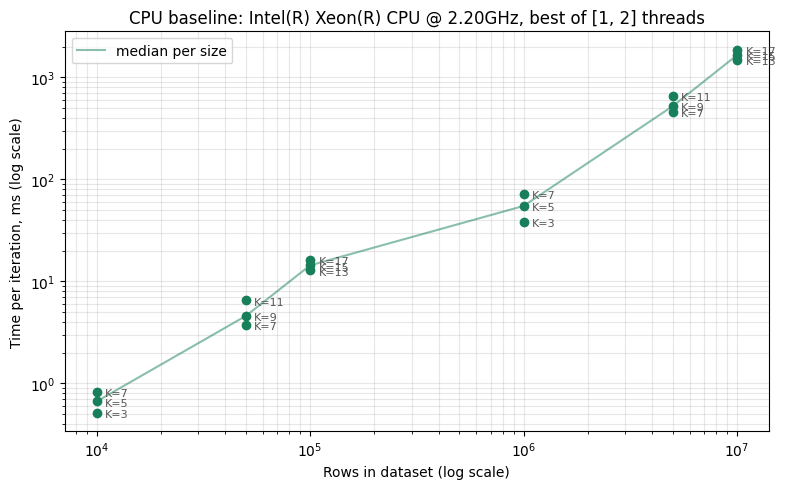

,file,rows,K,threads,per_iter_ms_median,per_iter_ms_by_threads,bench_iters,conv_iterations,conv_converged,conv_reason,conv_total_s,conv_final_assignment_change_fraction,empty_clusters,smallest_cluster,largest_cluster
0,synthetic_data_10000_rows_10_cols_3_clusters,10000,3,2,0.5121,1:0.8058; 2:0.5121,993,2,True,centroid_tolerance,0.0014,0.0000,0,3255,3407
1,synthetic_data_10000_rows_10_cols_5_clusters,10000,5,1,0.6637,1:0.6637; 2:0.6817,767,41,True,centroid_tolerance,0.3163,0.0000,0,669,5966
2,synthetic_data_10000_rows_10_cols_7_clusters,10000,7,2,0.8290,1:0.8470; 2:0.8290,350,33,True,centroid_tolerance,0.0299,0.0000,0,687,4245
3,synthetic_data_50000_rows_10_cols_7_clusters,50000,7,2,3.7419,1:3.9944; 2:3.7419,129,55,True,assignment_fraction_stable,0.2048,0.0001,1,0,14371
4,synthetic_data_50000_rows_10_cols_9_clusters,50000,9,2,4.5806,1:4.9395; 2:4.5806,92,60,True,centroid_tolerance,0.2738,0.0000,0,1818,16731
5,synthetic_data_50000_rows_10_cols_11_clusters,50000,11,1,6.5148,1:6.5148; 2:9.4880,79,56,True,assignment_fraction_stable,0.5933,0.0000,1,0,13712
6,synthetic_data_100000_rows_10_cols_13_clusters,100000,13,2,12.8242,1:14.7062; 2:12.8242,37,114,True,assignment_fraction_stable,1.4550,0.0000,2,0,15641
7,synthetic_data_100000_rows_10_cols_15_clusters,100000,15,2,14.3577,1:16.4306; 2:14.3577,34,140,True,assignment_fraction_stable,2.0280,0.0001,0,2208,26910
8,synthetic_data_100000_rows_10_cols_17_clusters,100000,17,2,16.2796,1:30.0062; 2:16.2796,32,57,True,assignment_fraction_stable,0.9199,0.0001,0,1397,23622
9,synthetic_data_1000000_rows_10_cols_3_clusters,1000000,3,2,38.5285,1:40.7553; 2:38.5285,20,78,True,assignment_fraction_stable,4.2537,0.0001,0,166323,666317


In [10]:
import matplotlib.pyplot as plt

s = summary.sort_values(["rows", "K"])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(s["rows"], s["per_iter_ms_median"], color="#17805A", zorder=3)
for _, r in s.iterrows():
    ax.annotate(f"K={int(r['K'])}", (r["rows"], r["per_iter_ms_median"]), textcoords="offset points",
                xytext=(6, -3), fontsize=8, color="#555555")
med = s.groupby("rows")["per_iter_ms_median"].median()
ax.plot(med.index, med.values, color="#17805A", alpha=0.5, label="median per size")
if s["rows"].nunique() > 1:
    ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Rows in dataset (log scale)")
ax.set_ylabel("Time per iteration, ms (log scale)")
ax.set_title(f"CPU baseline: {ENV['cpu_model']}, best of {THREADS_TO_TRY} threads" if HAVE_NUMBA else f"CPU baseline: {ENV['cpu_model']}")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "cpu_baseline_time_per_iteration.png", dpi=150)
plt.show()

cols = ["file", "rows", "K", "threads", "per_iter_ms_median", "per_iter_ms_by_threads", "bench_iters",
        "conv_iterations", "conv_converged", "conv_reason", "conv_total_s", "conv_final_assignment_change_fraction", "empty_clusters", "smallest_cluster", "largest_cluster"]
display(s[cols].round(4))

## 9. Package the results

In [11]:
zip_path = OUT_DIR / "cpu_baseline_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT_DIR.glob("*")):
        if p.is_file() and p.suffix in {".csv", ".json", ".png"}:
            z.write(p, p.name)
print("Saved", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
if SAVE_ASSIGNMENTS and IN_COLAB and ASSIGNMENTS_DIR.exists():   # copy after all timing is finished
    dest = OUT_DIR / "assignments"
    dest.mkdir(exist_ok=True)
    for p in sorted(ASSIGNMENTS_DIR.glob("*.csv")):
        shutil.copy2(p, dest / p.name)
    print("Assignments copied to", dest)
elif SAVE_ASSIGNMENTS:
    print("Assignments are in", ASSIGNMENTS_DIR)
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))

Saved /content/drive/MyDrive/kmeans_data/results_cpu_baseline_v3_aligned/cpu_baseline_results.zip (0.1 MB)
Assignments copied to /content/drive/MyDrive/kmeans_data/results_cpu_baseline_v3_aligned/assignments


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Fair-comparison contract

The three aligned notebooks now use the same experiment contract:

- **Canonical initial centroids:** `kmeans_data/results_gpu_atomic_v3/initial_centroids_*.csv`
- **Feature dtype:** float64
- **Centroid movement tolerance:** `1e-4`
- **Assignment change fraction tolerance:** `1e-4` = 0.01%
- **Stable assignment iterations:** 3 consecutive iterations
- **Maximum iterations:** 400
- **Empty cluster behavior:** retain the previous centroid

Each final result records `Initial centroid SHA256`.  
For a valid CPU-vs-Atomic-vs-Reduction comparison, the SHA-256 value for the
same dataset must be identical in all three outputs.

The CPU notebook additionally reports a fixed-iteration median timing over
repeats. Use this field for the cleanest CPU per-iteration performance baseline.
